## Extracting data examples for "Magic state cultivation on a superconducting quantum processor"

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np
from pathlib import Path 
import stim 
from typing import Optional, Callable, Dict, Type
import stimcirq 
import cirq 

DATA_DIR = "my_data_directory"

In [2]:

def get_data(figure_name, experiment_type_to_plot: str, 
             data_type_to_plot: str, 
             df: pd.DataFrame | None = None) -> dict[str, pd.DataFrame]:
    if df is None:
        df = pd.read_csv(Path(DATA_DIR + f"/{figure_name}/{experiment_type_to_plot}/{data_type_to_plot}.csv"))
        df = df.set_index(["basis", "theta", "shot"])
    data = {basis: df.loc[(basis)].groupby("theta").mean() for basis in df.index.unique("basis")}
    return data

## Fig 2 - plot the data and postselect raw data

In [3]:
FIGURE_NAME = "fig2"

Look at the cirq circuit

In [ ]:
# Define a dictionary mapping the custom cirq_type strings to their classes.
# stimcirq objects that are serializable (like DetAnnotation) should be included here.
STIMCIRQ_CUSTOM_TYPES: Dict[str, Type] = {
    'DetAnnotation': stimcirq.DetAnnotation,
    'ShiftCoordsAnnotation': stimcirq.ShiftCoordsAnnotation,
    'CumulativeObservableAnnotation': stimcirq.CumulativeObservableAnnotation
    # Add other specific stimcirq custom types if needed
}

def stimcirq_resolver(cirq_type: str) -> Optional[Callable]:
    """A custom JSON resolver for stimcirq objects."""
    return STIMCIRQ_CUSTOM_TYPES.get(cirq_type, None)

MY_RESOLVERS = [stimcirq_resolver] + cirq.protocols.json_serialization.DEFAULT_RESOLVERS

In [ ]:
path_with_subdirectories = Path(DATA_DIR + f"/{FIGURE_NAME}/cultivation/cirq_circuit_X.json")
cirq_circuit = cirq.read_json(path_with_subdirectories, resolvers=MY_RESOLVERS)
cirq_circuit

┌──┐               ┌──┐           ┌──┐                                   ┌───┐       ┌───┐                                                                              ┌───┐                       ┌──┐                        ┌──┐                       ┌───┐
(7, 8): ──────────────────────────────H──────────────────@──────────────────@────────────────────────────────────@────────────────@──────H───────────────────Y──────────────────────────────(Y-X^0.5)───Y───T───(Y-X^0.5)───H────@─────────────────────────────────────Y────────────────────────────────────────────@──────H───(Y-X^0.5)───Z───T^-1───(Y-X^0.5)───H───M('11')────────────────────────────────────
                                                         │                  │                                    │                │                                                                                              │                                                                                  │
(7, 9): ──────────────────────────────H──────────────────@──────────────────┼@───────────────────────────H───────┼───X───@───H────@──────X─────@─────H───────M('1')─────────────────────R───────────────────────────────────H────┼@────────────────────────────────────Y────────────────────────────────────────────┼@─────────────────────X──────────────────────H───M('7')─────────────────────────────────────
                                                                            ││                                   │       │                     │                                                                                 ││                                                                                 ││
(7, 10): ─────────────────────────────H───────────────────@────H────────────┼┼───────────────────────────────────┼───────@─────────────────────┼@────────────Y──────────────────────────────(Y-X^0.5)───X───T───(Y-X^0.5)───H────┼┼@───────────────────────────────────Y────────────────────────────────────────────┼┼@────H───(Y-X^0.5)───Y───T^-1───(Y-X^0.5)───H───M('15')────────────────────────────────────
                                                          │                 ││                                   │                             ││                                                                                │││                                                                                │││
(8, 7): ──────────────────────────────H───────────────────┼─────────────────┼┼───────────────────────@───────────┼────────────────────────────@┼┼────────────Y──────────────────────────────(Y-X^0.5)───Z───T───(Y-X^0.5)────────┼┼┼────H───@──────────────────────────Y───────────────────────────────────@───H────┼┼┼────────(Y-X^0.5)───Y───T^-1───(Y-X^0.5)───H───M('10')────────────────────────────────────
                                                          │                 ││                       │           │                            │││                                                                                │││        │                                                              │        │││
(8, 8): ──────────────────────────────H──────────────────@┼────H───@───X────@┼────H────────@─────X───@───H───────@───────@───X────@──────H────@┼┼────H───Y───M('0')─────────────────────R───────────────────────────────────H────@┼┼────X───@───H───@──────────────────Y───────────────────────────@───H───@────────@┼┼────────────────────Z──────────────────────H───M('6')─────────────────────────────────────
                                                         ││        │         │             │                             │        │            ││                                                                                 ││                │                                              │                 ││
(8, 9): ────(Y-X^0.5)───Z^(2*theta)───(Y-X^0.5)───Z^0────@┼────────┼───H─────@─────────────┼@────────────────X───────────@────────┼@───────────@┼────H───────Y──────────────────

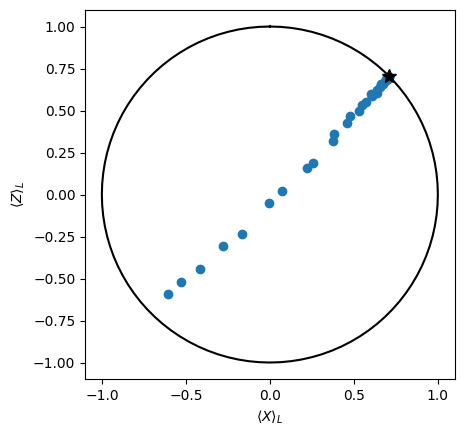

In [6]:
experiment_type_to_plot = "cultivation"
data_type_to_plot = "corrected_observables"
cultivation_data = get_data(FIGURE_NAME, experiment_type_to_plot, data_type_to_plot)

fig, ax = plt.subplots()
ax.plot(1 - 2 * cultivation_data["X"], 1 - 2 * cultivation_data["Z"], marker = 'o', linestyle="")
ax.plot([np.sin(t) for t in np.linspace(0, 2 * np.pi, 101)], 
        [np.cos(t) for t in np.linspace(0, 2 * np.pi, 101)], color="black")
ax.plot([1/np.sqrt(2)], [1/np.sqrt(2)], marker = "*", color="black", markersize=10)
ax.set_xlabel(r"$\langle X \rangle_L$")
ax.set_ylabel(r"$\langle Z \rangle_L$")
ax.set_aspect("equal")

In [7]:
# postselecting the data and plotting it 

experiment_type_to_plot = "cultivation"
data_type_to_plot = "raw_observables"
raw_obs_df = pd.read_csv(Path(DATA_DIR + f"/{FIGURE_NAME}/{experiment_type_to_plot}/{data_type_to_plot}.csv"))
raw_obs_df = raw_obs_df.set_index(["basis", "theta", "shot"])
dets_df =  pd.read_csv(Path(DATA_DIR + f"/{FIGURE_NAME}/{experiment_type_to_plot}/detection_events.csv"))
dets_df = dets_df.set_index(["basis", "theta", "shot"])
dets_df["any_detector"] = [any(row[1].values) for row in dets_df.iterrows()] # this may take a few minutes
shots_to_keep = dets_df.index[dets_df["any_detector"] == False]
postselected_shots = raw_obs_df.loc[shots_to_keep]

# format the data
postselected_data = get_data(FIGURE_NAME, "", "", df=postselected_shots)
raw_obs_data = get_data(FIGURE_NAME, "", "", df=raw_obs_df)

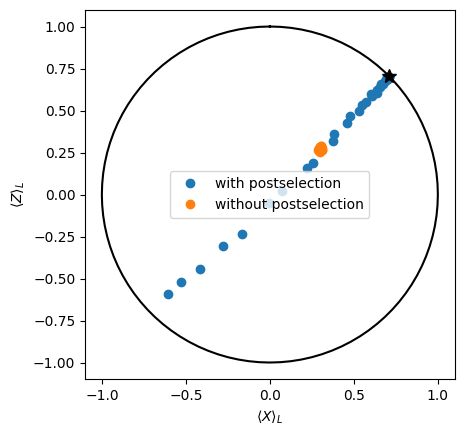

In [ ]:
fig, ax = plt.subplots()
ax.plot(1 - 2 * postselected_data["X"], 1 - 2 * postselected_data["Z"], marker = 'o', linestyle="", label="with postselection")
ax.plot(1 - 2 * raw_obs_data["X"], 1 - 2 * raw_obs_data["Z"], marker = 'o', linestyle="", label = "without postselection")
ax.plot([np.sin(t) for t in np.linspace(0, 2 * np.pi, 101)], 
        [np.cos(t) for t in np.linspace(0, 2 * np.pi, 101)], color="black")
ax.plot([1/np.sqrt(2)], [1/np.sqrt(2)], marker = "*", color="black", markersize=10)
ax.set_xlabel(r"$\langle X \rangle_L$")
ax.set_ylabel(r"$\langle Z \rangle_L$")
ax.set_aspect("equal")
ax.legend()

## Figure 3 - kickback tomography

In [8]:
FIGURE_NAME = "fig3"

Text(0, 0.5, 'total logical error')

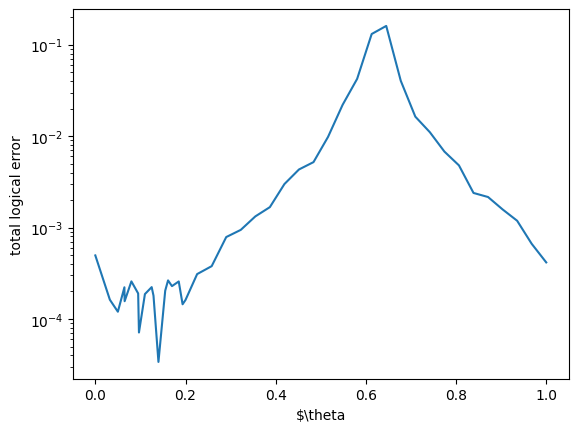

In [10]:
experiment_type_to_plot = "with_idle_rounds"
data_type_to_plot = "corrected_observables"
data = get_data(FIGURE_NAME, experiment_type_to_plot, data_type_to_plot)

fig, ax = plt.subplots()
ax.plot(data["X"].index.unique("theta").values, data["X"][data_type_to_plot].values)
ax.set_yscale("log")
ax.set_xlabel(r"$\theta")
ax.set_ylabel("total logical error")

## Figure 4 - grafting

In [11]:
FIGURE_NAME = "fig4"

In [12]:
# an example: postselecting the data and plotting it 

experiment_type_to_plot = "cultivation_N=2"
data_type_to_plot = "raw_observables"
raw_obs_df = pd.read_csv(Path(DATA_DIR + f"/{FIGURE_NAME}/{experiment_type_to_plot}/{data_type_to_plot}.csv"))
raw_obs_df = raw_obs_df.set_index(["basis", "theta", "shot"])
dets_df =  pd.read_csv(Path(DATA_DIR + f"/{FIGURE_NAME}/{experiment_type_to_plot}/detection_events.csv"))
dets_df = dets_df.set_index(["basis", "theta", "shot"])

# load stim circuit to find detectors to postselect on
stim_circuit = stim.Circuit.from_file(Path(DATA_DIR + f"/{FIGURE_NAME}/{experiment_type_to_plot}/stim_X.stim"))
idxs_to_postselect = [idx for idx, coords in stim_circuit.get_detector_coordinates().items() if len(coords) == 4] # all cultivation detectors have 4 coordinates
dets_df["any_cultivation_detector"] = [any(bool(row[1][i]) for i in idxs_to_postselect) for row in dets_df.iterrows()] # this may take a few minutes
shots_to_keep = dets_df.index[dets_df["any_cultivation_detector"] == False]
postselected_shots = raw_obs_df.loc[shots_to_keep]

/tmp/ipykernel_897979/163048010.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  dets_df["any_cultivation_detector"] = [any(bool(row[1][i]) for i in idxs_to_postselect) for row in dets_df.iterrows()] # this may take a few minutes


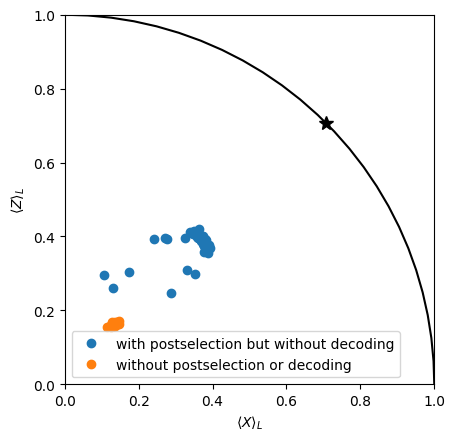

In [13]:
# format the data
postselected_data = get_data(FIGURE_NAME, "", "", df=postselected_shots)
raw_obs_data = get_data(FIGURE_NAME, "", "", df=raw_obs_df)

fig, ax = plt.subplots()
ax.plot(1 - 2 * postselected_data["X"], 1 - 2 * postselected_data["Z"], marker = 'o', linestyle="", label="with postselection but without decoding")
ax.plot(1 - 2 * raw_obs_data["X"], 1 - 2 * raw_obs_data["Z"], marker = 'o', linestyle="", label = "without postselection or decoding")
ax.plot([np.sin(t) for t in np.linspace(0, 2 * np.pi, 101)], 
        [np.cos(t) for t in np.linspace(0, 2 * np.pi, 101)], color="black")
ax.plot([1/np.sqrt(2)], [1/np.sqrt(2)], marker = "*", color="black", markersize=10)
ax.set_xlabel(r"$\langle X \rangle_L$")
ax.set_ylabel(r"$\langle Z \rangle_L$")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.legend()